# Class Imbalance and Decision Threshold

Only about 11% of stays are readmitted within 30 days. This notebook asks three questions about the random forest, which performed as well as or slightly better than the other two models:


1. Does resampling the training data work better than class weights?
2. Which probability cutoff best balances precision and recall for the `<30` class?
3. What does the confusion matrix look like at that cutoff?

The test set is used only once, at the end.



### Libraries

In [12]:
import sys
sys.path.insert(0, "..")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             precision_recall_curve, ConfusionMatrixDisplay)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC

from scripts.data import fetch_raw
from scripts.split import patient_split, SEED
from scripts.preprocess import preprocess_data

FIGS, MODELS = Path("../reports/figures"), Path("../models")

## Load data and split

Same patient split. All drug columns are kept, as in the tree models.

In [13]:
df, _ = preprocess_data(fetch_raw())

X = df.drop(columns=["encounter_id", "patient_nbr", "readmitted", "readmit_30"])
y = df["readmit_30"]
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

train_idx, test_idx = patient_split(y, df["patient_nbr"])
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = df["patient_nbr"].iloc[train_idx]
print(len(X_train), "train,", len(X_test), "test")

79473 train, 19867 test


## Reuse the tuned random forest

The three models performed similarly. Random forest had the highest mean ROC-AUC across five patient splits (0.670, vs. 0.668 for XGBoost and 0.660 for logistic regression) and was slightly ahead of logistic regression on every split, so we use it here. We keep the settings chosen in notebook 04 and only change how the model handles the class imbalance.


In [14]:
rf_params = joblib.load(MODELS / "random_forest.joblib").named_steps["clf"].get_params()
print({k: rf_params[k] for k in ["n_estimators", "max_depth", "min_samples_leaf", "class_weight"]})

KeyError: 'min_samples_leaf'

## Three ways to handle the imbalance

- **Class weights**: mistakes on readmitted stays count more during training 
- **Random oversampling**: copy readmitted training stays until both classes are the same size.
- **SMOTENC**: create synthetic readmitted stays between real ones; handles categorical columns.

Resampling sits inside an `imblearn` pipeline, so it runs only when the model is fit, never on validation or test data.

In [ ]:
prep = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

def forest(class_weight):
    """Random forest with the tuned settings and the given class weighting."""
    return RandomForestClassifier(**{**rf_params, "class_weight": class_weight})

# numeric columns that only hold 0 or 1 are really categories
flag_cols = [c for c in num_cols if set(X[c].unique()) <= {0, 1}]
print("0/1 flags:", flag_cols)

versions = {
    "Class weights": Pipeline([
        ("prep", prep),
        ("clf", forest("balanced")),
    ]),
    "Random oversampling": ImbPipeline([
        ("prep", prep),
        ("sample", RandomOverSampler(random_state=SEED)),
        ("clf", forest(None)),
    ]),
    "SMOTENC": ImbPipeline([
        ("sample", SMOTENC(categorical_features=cat_cols + flag_cols, random_state=SEED)),
        ("prep", prep),
        ("clf", forest(None)),
    ]),
}

0/1 flags: ['a1c_tested', 'glucose_tested', 'a1c_tested_and_changed', 'medicare', 'medicaid']


## Compare with grouped cross-validation

3 folds on the training set only, with each patient's stays kept in one fold. The test set is not used to choose a method. We pick the method with the highest average precision (AP).

In [ ]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

rows = []
for name, model in versions.items():
    scores = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv,
                            scoring=["roc_auc", "average_precision"])
    rows.append({"method": name,
                 "cv_roc_auc": scores["test_roc_auc"].mean(),
                 "cv_ap": scores["test_average_precision"].mean()})

compare = pd.DataFrame(rows).set_index("method").round(3)
compare

,cv_roc_auc,cv_ap
method,,
Class weights,0.673,0.217
Random oversampling,0.671,0.216
SMOTENC,0.572,0.138


In [ ]:
best_name = compare["cv_ap"].idxmax()
best_model = versions[best_name]
print("Best method:", best_name)

Best method: Class weights


What we see from these results is that the model was already set up pretty sensibly. The additional techniques, synthetic data and threshold tuning, didn't improve it. The real limit is the data, it doesn't contain enough information to predict readmission much better. 

## Sweep the decision threshold

Each training stay gets a predicted probability from a model that did not see it (out-of-fold). We compute precision, recall, and F1 at every cutoff and keep the cutoff with the highest F1, which balances precision and recall for the `<30` class.

In [ ]:
oof = cross_val_predict(best_model, X_train, y_train, groups=groups_train,
                        cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
prec, rec = prec[:-1], rec[:-1]          # the last point has no matching threshold
f1 = 2 * prec * rec / (prec + rec + 1e-12)

best_i = np.argmax(f1)
threshold = thr[best_i]
print(f"Chosen threshold {threshold:.3f}: precision {prec[best_i]:.3f}, "
      f"recall {rec[best_i]:.3f}, F1 {f1[best_i]:.3f}")

Chosen threshold 0.513: precision 0.211, recall 0.436, F1 0.285


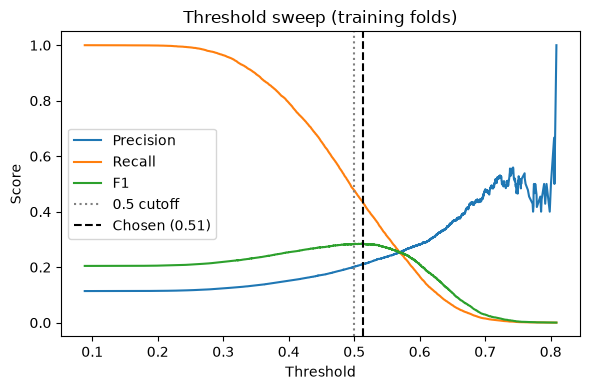

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thr, prec, label="Precision")
ax.plot(thr, rec, label="Recall")
ax.plot(thr, f1, label="F1")
ax.axvline(0.5, color="grey", ls=":", label="0.5 cutoff")
ax.axvline(threshold, color="k", ls="--", label=f"Chosen ({threshold:.2f})")
ax.set(xlabel="Threshold", ylabel="Score", title="Threshold sweep (training folds)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "threshold_sweep.png", dpi=300)
plt.show()

## Test set: 0.5 cutoff vs chosen threshold

The chosen method is trained on the full training set and evaluated once on the test set.

In [ ]:
final = clone(best_model).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]

rows = []
for label, t in [("0.5 cutoff", 0.5), ("Chosen threshold", threshold)]:
    pred = (proba >= t).astype(int)
    rows.append({"cutoff": label, "threshold": round(t, 3),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "flagged": pred.mean()})

test_results = pd.DataFrame(rows).round(3)
test_results

,cutoff,threshold,precision,recall,f1,flagged
0,0.5 cutoff,0.500,0.198,0.492,0.282,0.283
1,Chosen threshold,0.513,0.203,0.439,0.278,0.246


## Confusion matrix at the chosen threshold

Rows are the true outcome, and columns are the prediction. The bottom-right cell counts readmissions the model caught, the top-right counts false alarms.

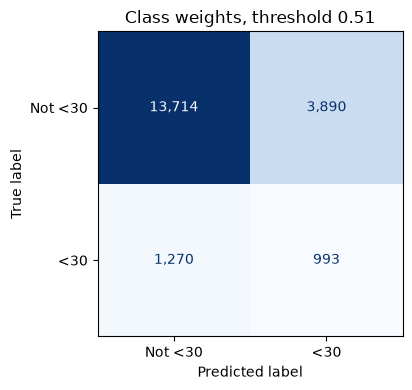

In [ ]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba >= threshold).astype(int),
    display_labels=["Not <30", "<30"], cmap="Blues",
    values_format=",d", colorbar=False, ax=ax)
ax.set_title(f"{best_name}, threshold {threshold:.2f}")
fig.tight_layout()
fig.savefig(FIGS / "confusion_matrix_chosen.png", dpi=300)
plt.show()

### Save

In [ ]:
compare.to_csv(FIGS / "imbalance_methods.csv")
test_results.to_csv(FIGS / "threshold_results.csv", index=False)